## 뉴스 텍스트 단어 빈도 분석

### 1. 기사 정리
- 출처: 뉴시스 (2025.02.06)
- 링크: https://www.newsis.com/view/NISX20250205_0003054569

#### 요약
- 서울시가 2040 서울시 공원녹지기본계획을 조건부 가결
- 비전: 기후 위기에 선도적으로 대응하는 정원도시 서울
- 목표: 2040년까지 공원녹지율 31.2%, 탄소 흡수량 8.8% 증가
- 주요 내용: 입체공원, 개방형 녹지, 중점녹화지구, 방재 기능 강화
- 특징: 공원 면적을 늘리기보다 녹지의 질을 높이는 데 초점

### 1-1. 실행 환경 및 불용어
- 불용어: 시, 기본, 반영, 제시, 다양, 량, 서울, 기자, 뉴시스, 이번, 지난, 관계자, 국장
- 라이브러리 버전은 아래 코드 실행 결과 참고

In [1]:
import sys, matplotlib, wordcloud, kiwipiepy
print("Python:", sys.version.split()[0])
print("matplotlib:", matplotlib.__version__)
print("wordcloud:", wordcloud.__version__)
print("kiwipiepy:", kiwipiepy.__version__)

Python: 3.9.6
matplotlib: 3.9.4
wordcloud: 1.9.6
kiwipiepy: 0.24.1


### 2. 데이터 불러오기

In [2]:
with open('news.txt', 'r', encoding='utf-8') as f:
    text = f.read()

print(text[:300])

기후변화, 방재 위한 공원녹지 기능강화 목표
공원녹지율 31.2% 달성해 탄소흡수량 8.8%↑
"공원 양적 확충이 아닌 녹지 질적 제고 지향"

[서울=뉴시스] 이재은 기자 = 서울시 공원들이 입체공원과 개방형 녹지 등 다양한 모습으로 업그레이드 된다. 
기후 변화 대응을 위해 녹지 기능이 강화된다.

시는 지난 5일  제1차 도시계획위원회를 개최하고 
2040 서울시 공원녹지기본계획(안)'을 조건부 가결했다고 6일 밝혔다.

이번 공원녹지 기본계획은 지난 2023년 수립한 '2040 서울도시기본계획'과 정합성을 맞추고, 
'기후 
ERROR! Session/line number was not unique in database. History logging moved to new session 2


### 3. 전처리
특수문자(▲, 따옴표, 괄호 등)와 불필요한 공백 제거

In [3]:
import re

clean_text = re.sub(r'[^가-힣A-Za-z0-9\s]', ' ', text)
clean_text = re.sub(r'\s+', ' ', clean_text).strip()

print(clean_text[:300])

기후변화 방재 위한 공원녹지 기능강화 목표 공원녹지율 31 2 달성해 탄소흡수량 8 8 공원 양적 확충이 아닌 녹지 질적 제고 지향 서울 뉴시스 이재은 기자 서울시 공원들이 입체공원과 개방형 녹지 등 다양한 모습으로 업그레이드 된다 기후 변화 대응을 위해 녹지 기능이 강화된다 시는 지난 5일 제1차 도시계획위원회를 개최하고 2040 서울시 공원녹지기본계획 안 을 조건부 가결했다고 6일 밝혔다 이번 공원녹지 기본계획은 지난 2023년 수립한 2040 서울도시기본계획 과 정합성을 맞추고 기후 위기에 선도적으로 대응하는 정원도시 서울 이


### 4. 형태소 분석 (명사 추출)
Kiwi 형태소 분석기로 일반명사(NNG)와 고유명사(NNP)만 추출

In [4]:
from kiwipiepy import Kiwi

kiwi = Kiwi()
tokens = kiwi.tokenize(clean_text)

nouns = [t.form for t in tokens if t.tag in ['NNG', 'NNP']]

print(len(nouns))
print(nouns[:50])

281
['기후', '변화', '방재', '공원', '녹지', '기능', '강화', '목표', '공원', '녹지', '달성', '탄소', '흡수', '량', '공원', '양', '확충', '녹지', '질', '제고', '지향', '서울', '뉴시스', '이재은', '기자', '서울시', '공원', '입체', '공원', '개방', '녹지', '다양', '모습', '업그레이드', '기후', '변화', '대응', '녹지', '기능', '강화', '시', '도시', '계획', '위원회', '개최', '서울시', '공원', '녹지', '기본', '계획']


### 5. 불용어 제거 및 빈도 계산

In [5]:
from collections import Counter

count = Counter(nouns)
print(count.most_common(30))

[('공원', 21), ('녹지', 20), ('계획', 14), ('도시', 10), ('시', 7), ('기본', 7), ('기후', 6), ('서울시', 6), ('대응', 5), ('기능', 4), ('목표', 4), ('확충', 4), ('서울', 4), ('녹색', 4), ('반영', 4), ('변화', 3), ('방재', 3), ('강화', 3), ('탄소', 3), ('질', 3), ('입체', 3), ('다양', 3), ('위기', 3), ('정원', 3), ('제시', 3), ('녹화', 3), ('달성', 2), ('흡수', 2), ('량', 2), ('양', 2)]


#### 불용어 선정

불용어 없이 빈도를 확인한 뒤, 기사 주제와 관련 없는 단어를 제거했습니다.

| 제거한 단어 | 이유 |
|---|---|
| 시 | "시는 ~했다"의 '시'로, '서울시'와 중복 |
| 기본 | '기본계획'이 쪼개진 조각으로 단독 의미 없음 |
| 반영, 제시, 다양 | 기사에서 흔히 쓰는 서술 단어 |
| 량 | '흡수량'에서 분리된 조각 |
| 서울 | '[서울=뉴시스]' 등 기사 형식에서 등장 |
| 기자, 뉴시스, 이번, 지난, 관계자, 국장 | 기사 형식 단어 |

**남긴 단어**
- 질, 양: 한 글자지만 '질적 제고', '양적 확충'에서 나온 핵심 단어라서 남김
- 계획: 기사가 계획 발표 내용이므로 남김

In [6]:
stopwords = ['시', '기본', '반영', '제시', '다양', '량', '서울',
             '기자', '뉴시스', '이번', '지난', '관계자', '국장']

filtered = [w for w in nouns if w not in stopwords]

count = Counter(filtered)
top20 = count.most_common(20)
print(top20)

[('공원', 21), ('녹지', 20), ('계획', 14), ('도시', 10), ('기후', 6), ('서울시', 6), ('대응', 5), ('기능', 4), ('목표', 4), ('확충', 4), ('녹색', 4), ('변화', 3), ('방재', 3), ('강화', 3), ('탄소', 3), ('질', 3), ('입체', 3), ('위기', 3), ('정원', 3), ('녹화', 3)]


### 6. 상위 20개 단어 막대그래프

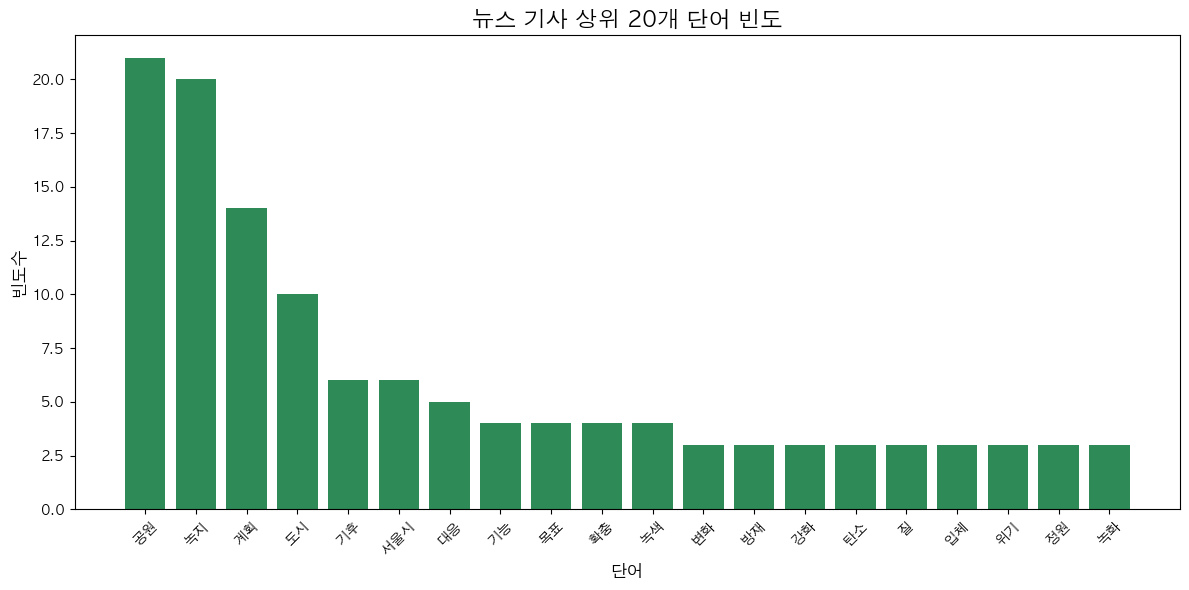

In [7]:
import matplotlib.pyplot as plt

plt.rcParams['font.family'] = 'AppleGothic'
plt.rcParams['axes.unicode_minus'] = False

words = [w for w, c in top20]
counts = [c for w, c in top20]

plt.figure(figsize=(12, 6))
plt.bar(words, counts, color='seagreen')
plt.title('뉴스 기사 상위 20개 단어 빈도', fontsize=16)
plt.xlabel('단어', fontsize=12)
plt.ylabel('빈도수', fontsize=12)
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig('bar.png', dpi=150)
plt.show()

### 7. 워드클라우드
불용어를 제거한 같은 빈도 결과로 워드클라우드를 생성합니다.

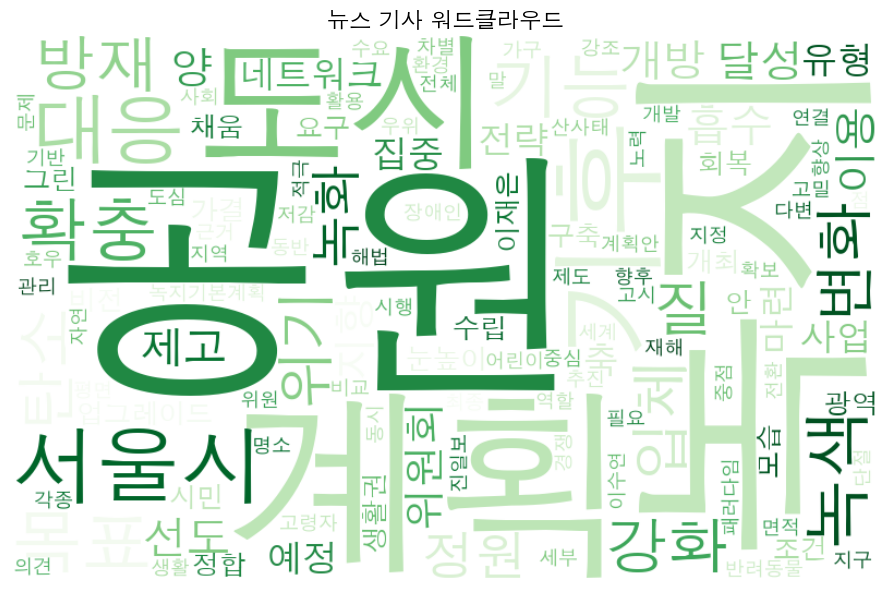

In [8]:
from wordcloud import WordCloud

wc = WordCloud(
    font_path='/System/Library/Fonts/Supplemental/AppleGothic.ttf',
    width=800,
    height=500,
    background_color='white',
    colormap='Greens'
).generate_from_frequencies(count)

plt.figure(figsize=(10, 6))
plt.imshow(wc, interpolation='bilinear')
plt.axis('off')
plt.title('뉴스 기사 워드클라우드', fontsize=16)
plt.tight_layout()
plt.savefig('wordcloud.png', dpi=150)
plt.show()

### 8. 결론

- 상위 단어는 '공원', '녹지', '계획', '도시', '기후' 순으로, 기사의 주제인
  "기후변화 대응을 위한 도시 녹지 계획"과 잘 일치했다.
- '탄소', '방재', '위기' 같은 단어를 통해 녹지가 휴식 공간을 넘어
  기후 위기 대응 수단으로 다뤄지고 있음을 알 수 있었다.
- '질'과 '양'은 빈도는 낮지만 "양적 확충이 아닌 질적 제고"라는 기사의
  핵심 메시지를 담고 있어, 빈도만으로는 중요도를 모두 판단하기 어렵다는 점도 확인했다.

##### 배운 점 
- 형태 분석기가 '기본계획'을 '기본'과 '계획'으로, '흡수량'을 '흡수'와 '량'으로 나누는 걸 보고, 단어를 그대로 세면 의미가 쪼개질 수 있다는 걸 알게 됐다. 그래서 결과를 직접 보고 불용어를 고르는 과정이 중요하다고 느꼈다.